# Qualitative content analysis of misclassified pairs and tests of H2/H3

**RQ2:** Which types of errors do the classifiers make, and what do they reveal about the limits of lexical competency matching for mentor recommendation?

Input: `results/primary_test_predictions.csv` from notebook 04. All test pairs misclassified by at least one classifier on the primary split are coded (conventional / inductive content analysis). The author read each competency, course title, course sentence, the title/sentence sub-labels and the model outputs, wrote a short memo, and grouped the memos into six categories. Missed-match categories are recorded by record ID below; false-match categories were then fixed as explicit rules so that the coding is reproducible. Hypotheses H2 and H3 were derived from the two dominant categories.

In [1]:
from pathlib import Path
import json
import numpy as np, pandas as pd
from scipy import stats
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/Assignment3_TulegenovaK')
except ImportError:
    BASE = Path.cwd()
RESULT = BASE / 'results'
d = pd.read_csv(RESULT / 'primary_test_predictions.csv')
M = ['LR', 'RF', 'GB']
d['n_models_wrong'] = sum((d['pred_' + m] != d.eval_all).astype(int) for m in M)
e = d[d.n_models_wrong > 0].copy()
print('Test pairs:', len(d), '| misclassified by at least one model:', len(e),
      '| missed matches:', int((e.eval_all == 1).sum()), '| false matches:', int((e.eval_all == 0).sum()))

Test pairs: 216 | misclassified by at least one model: 95 | missed matches: 43 | false matches: 52


## 1. Codebook

| Category | Type | Definition | Example from the data |
|---|---|---|---|
| Paraphrase without shared terms | FN | Relevant pair in which the competency and the course text express the same idea with different words | “image recognition” – “computational methods … for various computer vision applications” |
| Abstract or generic competency | FN | Competency is broad or managerial, so no specific course wording can signal it | “integrate strategic foundation in daily performance” |
| Debatable label or noisy text | FN | The reference label is questionable or the sentence is very short, repeated or garbled | “query languages” – “REST APIs.” |
| Partial relevance | FP | Only one sub-label is positive (title-level or sentence-level), so the full label is 0 | “SAS Data Management” – “Data Modeling and Design” |
| Shared generic vocabulary | FP | A common word (e.g. “security”, “environment”) creates overlap without relevance; rule: min cosine ≥ 0.02 or sentence Jaccard ≥ 0.08 | – |
| Unrelated pair, low-signal score | FP | Unrelated pair with near-zero similarity that was still accepted | “MATLAB” – a course on UK politics |

## 2. Coding

In [2]:
# Missed matches (FN) coded manually from the memos; all other FN were coded as paraphrase.
ABSTRACT = 'R0245 R0344 R0423 R0519 R0704 R0775 R0998 R1039 R1074 R1082'.split()
DEBATABLE = 'R0061 R0722 R0805 R0820 R1059'.split()

def code(r):
    if r.eval_all == 1:
        if r.record_id in ABSTRACT: return 'FN: abstract or generic competency'
        if r.record_id in DEBATABLE: return 'FN: debatable label or noisy text'
        return 'FN: paraphrase without shared terms'
    if r.eval_all_tit != r.eval_all_sen: return 'FP: partial relevance (title or sentence only)'
    if r.cos_min >= 0.02 or r.jac_sent >= 0.08: return 'FP: shared generic vocabulary'
    return 'FP: unrelated pair, low-signal score'

e['category'] = e.apply(code, axis=1)
CATS = ['FN: paraphrase without shared terms', 'FN: abstract or generic competency', 'FN: debatable label or noisy text',
        'FP: partial relevance (title or sentence only)', 'FP: shared generic vocabulary', 'FP: unrelated pair, low-signal score']
print(e.category.value_counts().reindex(CATS).to_string())
per_model = pd.DataFrame({m: e[e['pred_' + m] != e.eval_all].category.value_counts() for m in M}).reindex(CATS).fillna(0).astype(int)
print('\nErrors per category and model:')
print(per_model.to_string())
cols = ['record_id', 'skill_label', 'course_title', 'matched_course_sentence', 'eval_all', 'eval_all_tit', 'eval_all_sen',
        'pred_LR', 'pred_RF', 'pred_GB', 'n_models_wrong', 'category']
e[cols].to_csv(RESULT / 'error_coding.csv', index=False)

category
FN: paraphrase without shared terms               28
FN: abstract or generic competency                10
FN: debatable label or noisy text                  5
FP: partial relevance (title or sentence only)    23
FP: shared generic vocabulary                      6
FP: unrelated pair, low-signal score              23

Errors per category and model:
                                                LR  RF  GB
category                                                  
FN: paraphrase without shared terms             26  12  11
FN: abstract or generic competency              10   5   5
FN: debatable label or noisy text                5   3   2
FP: partial relevance (title or sentence only)  13  19  22
FP: shared generic vocabulary                    4   6   6
FP: unrelated pair, low-signal score             1  16  20


In [3]:
pd.set_option('display.max_colwidth', 80)
for c in CATS:
    print('\n===', c)
    print(e[e.category == c][['record_id', 'skill_label', 'course_title', 'matched_course_sentence']].head(3).to_string(index=False))


=== FN: paraphrase without shared terms
record_id                      skill_label                    course_title                                                                          matched_course_sentence
    R0063    conduct quantitative research                Machine Learning                                                                  Statistical regression methods.
    R0115       analyse business processes Creating Domain Value with Data                                 Alignment of the technical environment with business strategies.
    R0136 track key performance indicators Creating Domain Value with Data The role of analytics in organizational decision-making and the ways it can improve performance.

=== FN: abstract or generic competency
record_id                                         skill_label                                course_title                                                                                                                              

## 3. Hypotheses derived from the content analysis

* **H2:** relevant pairs that a classifier misses have lower lexical overlap (minimum cosine similarity) than relevant pairs it detects. Test: one-sided Mann–Whitney U, effect size rank-biserial r.
* **H3:** among non-relevant pairs, false matches are more often partially relevant than correctly rejected pairs. Test: Fisher’s exact test (odds ratio).

In [4]:
h2 = {}
for m in M:
    pos = d[d.eval_all == 1]
    fn, tp = pos[pos['pred_' + m] == 0], pos[pos['pred_' + m] == 1]
    u = stats.mannwhitneyu(fn.cos_min, tp.cos_min, alternative='less')
    h2[m] = dict(n_FN=len(fn), n_TP=len(tp), median_FN=fn.cos_min.median(), median_TP=tp.cos_min.median(),
                 U=u.statistic, p=u.pvalue, r_rank_biserial=1 - 2 * u.statistic / (len(fn) * len(tp)),
                 FN_zero_overlap=(fn.cos_min == 0).mean(), TP_zero_overlap=(tp.cos_min == 0).mean())
h2 = pd.DataFrame(h2).T
print('H2 (lexical overlap of missed vs detected matches)')
print(h2.round(4).to_string())

h3 = {}
for m in M:
    neg = d[d.eval_all == 0]
    partial = neg.eval_all_tit != neg.eval_all_sen
    fp = neg['pred_' + m] == 1
    table = pd.crosstab(fp, partial).values
    odds, p = stats.fisher_exact(table)
    h3[m] = dict(n_FP=int(fp.sum()), FP_partial=partial[fp].mean(), TN_partial=partial[~fp].mean(), odds_ratio=odds, p=p)
h3 = pd.DataFrame(h3).T
print('\nH3 (partial relevance among false matches vs correct rejections)')
print(h3.round(4).to_string())
json.dump(dict(counts=e.category.value_counts().to_dict(), per_model=per_model.to_dict(), H2=h2.to_dict('index'),
               H3=h3.to_dict('index')), open(RESULT / 'qual.json', 'w'), indent=2, default=float)

H2 (lexical overlap of missed vs detected matches)
    n_FN  n_TP  median_FN  median_TP      U       p  r_rank_biserial  FN_zero_overlap  TP_zero_overlap
LR  41.0  43.0        0.0     0.0559   87.0  0.0000           0.9013           0.6341           0.0465
RF  20.0  64.0        0.0     0.0398  189.5  0.0000           0.7039           0.7500           0.2031
GB  18.0  66.0        0.0     0.0337  260.5  0.0001           0.5614           0.6111           0.2576

H3 (partial relevance among false matches vs correct rejections)
    n_FP  FP_partial  TN_partial  odds_ratio       p
LR  18.0      0.7222      0.2632      7.2800  0.0003
RF  41.0      0.4634      0.2637      2.4110  0.0284
GB  48.0      0.4583      0.2500      2.5385  0.0201


## 4. Figures used in the paper

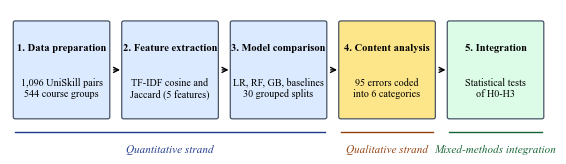

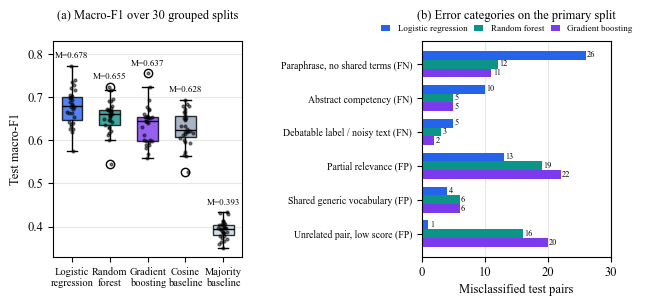

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'], 'font.size': 9})

# Figure 1: research workflow
fig, ax = plt.subplots(figsize=(7.0, 1.75)); ax.axis('off'); ax.set_xlim(0, 100); ax.set_ylim(0, 30)
boxes = [(1, '1. Data preparation', '1,096 UniSkill pairs\n544 course groups', '#dbeafe'),
         (21, '2. Feature extraction', 'TF-IDF cosine and\nJaccard (5 features)', '#dbeafe'),
         (41, '3. Model comparison', 'LR, RF, GB, baselines\n30 grouped splits', '#dbeafe'),
         (61, '4. Content analysis', f'{len(e)} errors coded\ninto 6 categories', '#fde68a'),
         (81, '5. Integration', 'Statistical tests\nof H0-H3', '#dcfce7')]
for x, t, s, c in boxes:
    ax.add_patch(FancyBboxPatch((x, 6), 17, 21, boxstyle='round,pad=0.4', fc=c, ec='#334155', lw=0.8))
    ax.text(x + 8.5, 21.5, t, ha='center', va='center', fontweight='bold', fontsize=7.6)
    ax.text(x + 8.5, 12.5, s, ha='center', va='center', fontsize=7.3)
for x in [18.6, 38.6, 58.6, 78.6]:
    ax.annotate('', xy=(x + 2.2, 16.5), xytext=(x, 16.5), arrowprops=dict(arrowstyle='->', lw=1))
for x0, x1, txt, col in [(1, 58, 'Quantitative strand', '#1e3a8a'), (61, 78, 'Qualitative strand', '#92400e'),
                         (81, 98, 'Mixed-methods integration', '#166534')]:
    ax.plot([x0, x1], [2.6, 2.6], color=col, lw=1)
    ax.text((x0 + x1) / 2, 0, txt, ha='center', va='top', fontsize=8, style='italic', color=col)
fig.savefig(RESULT / 'fig1_workflow.png', dpi=300, bbox_inches='tight'); plt.show()

# Figure 2: (a) macro-F1 over 30 splits, (b) error categories per model
R = pd.read_csv(RESULT / 'repeated_metrics.csv')
order = ['LR', 'RF', 'GB', 'Cosine', 'Majority']
names = {'LR': 'Logistic\nregression', 'RF': 'Random\nforest', 'GB': 'Gradient\nboosting',
         'Cosine': 'Cosine\nbaseline', 'Majority': 'Majority\nbaseline'}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 2.8), gridspec_kw={'wspace': 0.95})
data = [R[R.method == m].macro_f1 for m in order]
bp = a1.boxplot(data, patch_artist=True, widths=0.55, medianprops=dict(color='black'))
for p, c in zip(bp['boxes'], ['#2563eb', '#0d9488', '#7c3aed', '#94a3b8', '#cbd5e1']):
    p.set_facecolor(c); p.set_alpha(0.8)
for i, v in enumerate(data):
    a1.scatter(np.random.default_rng(i).normal(i + 1, 0.06, len(v)), v, s=4, color='black', alpha=0.5, zorder=3)
    a1.text(i + 1, v.max() + 0.018, f'M={v.mean():.3f}', ha='center', fontsize=6.5)
a1.set_xticks(range(1, 6), [names[m] for m in order], fontsize=7.5); a1.set_ylabel('Test macro-F1')
a1.grid(axis='y', alpha=0.3); a1.set_axisbelow(True); a1.set_ylim(0.33, 0.83)
a1.set_title('(a) Macro-F1 over 30 grouped splits', fontsize=9, pad=16)
lab = ['Paraphrase, no shared terms (FN)', 'Abstract competency (FN)', 'Debatable label / noisy text (FN)',
       'Partial relevance (FP)', 'Shared generic vocabulary (FP)', 'Unrelated pair, low score (FP)']
yy, h = np.arange(len(CATS)), 0.26
for j, (m, c) in enumerate(zip(M, ['#2563eb', '#0d9488', '#7c3aed'])):
    b = a2.barh(yy + (j - 1) * h, per_model[m].values, h, color=c,
                label={'LR': 'Logistic regression', 'RF': 'Random forest', 'GB': 'Gradient boosting'}[m])
    a2.bar_label(b, fontsize=6, padding=1)
a2.set_yticks(yy, lab, fontsize=7); a2.invert_yaxis(); a2.set_xlabel('Misclassified test pairs'); a2.set_xlim(0, 30)
a2.legend(fontsize=6.5, frameon=False, loc='lower center', bbox_to_anchor=(0.45, 1.0), ncol=3, handlelength=1, columnspacing=0.8)
a2.grid(axis='x', alpha=0.3); a2.set_axisbelow(True)
a2.set_title('(b) Error categories on the primary split', fontsize=9, pad=16)
fig.savefig(RESULT / 'fig2_panels.png', dpi=300, bbox_inches='tight'); plt.show()

## 5. Interpretation

Missed matches are mostly paraphrases with no shared weighted terms, so lexical features cannot detect them (H2). False matches are mostly pairs relevant at only one level (H3) or, for the tree-based models, unrelated pairs accepted at very low similarity. These findings motivate semantic features and human review of suggested mentors.